# 02 — Price Models with PySpark MLlib
**Project:** Predicting Airbnb Listing Prices and Analyzing Key Drivers of Pricing Using Distributed Data Processing (PySpark)
**Course:** BAN5600

This notebook answers RQ1 (which features drive price) and RQ2 (how well price can be predicted).
It trains five models of log nightly price on the same 80/20 split:

| Model | Purpose |
|---|---|
| Baseline | median log price of each neighborhood × room type in the training data |
| OLS linear regression | unregularized hedonic regression |
| Elastic Net linear regression | regularized hedonic regression, tuned by 5-fold CV |
| Random forest | non-linear tree ensemble, tuned by 5-fold CV |
| Gradient-boosted trees | sequential tree ensemble, tuned by 5-fold CV |

Every learned model is a single Spark ML `Pipeline` (indexing, one-hot encoding, median imputation,
assembly, estimator), so all preprocessing is re-fit inside each cross-validation fold.

## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import Imputer, OneHotEncoder, StringIndexer, VectorAssembler
from pyspark.ml.regression import GBTRegressor, LinearRegression, RandomForestRegressor
from pyspark.ml.stat import Summarizer
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.sql import Window, functions as F

CODE_DIR = Path.cwd() if Path.cwd().name == "code" else Path.cwd() / "code"
sys.path.insert(0, str(CODE_DIR))
import airbnb_prep as prep
import plot_style as ps

PROJECT_DIR = CODE_DIR.parent
DATA_PATH = PROJECT_DIR / "listings.csv"
FIG_DIR, OUT_DIR, MODEL_DIR = PROJECT_DIR / "figures", PROJECT_DIR / "outputs", PROJECT_DIR / "models"
for d in (FIG_DIR, OUT_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

SEED = 42
spark = prep.get_spark("Airbnb-NYC-Models")
ps.apply()
print("Spark version:", spark.version)

Spark version: 4.2.0


## 2. Data and features

In [2]:
listings = prep.load_listings(spark, str(DATA_PATH))
sample, (p01, p99) = prep.analytic_sample(listings)
data = prep.add_model_features(sample).cache()
print(f"Analytic sample: {data.count():,} listings (price trimmed to ${p01:,.2f}-${p99:,.2f})")

Analytic sample: 19,018 listings (price trimmed to $43.27-$1,997.43)


Borough is left out of the feature set because every neighborhood belongs to exactly one borough
(rare neighborhoods are pooled as "Other <borough>"), so borough dummies would be perfectly collinear
with neighborhood dummies in the linear models. Estimated revenue is excluded because it is
computed from price (target leakage).

In [3]:
CAT = ["neighbourhood_grp", "room_type", "property_grp", "stay_type", "license_status"]
NUM = [
    "latitude", "longitude", "km_to_midtown",
    "accommodates", "bedrooms", "beds", "bathrooms", "shared_bath",
    "amenities_count", *prep.AMENITY_FLAGS,
    "log_min_nights", "availability_30", "availability_365",
    "has_reviews", "log_reviews", "log_reviews_ltm",
    "review_scores_rating", "review_scores_cleanliness", "review_scores_location", "review_scores_value",
    "is_superhost", "identity_verified", "hosts_time_as_host_years", "log_host_listings",
]
# Feature families used for grouped (permutation) importance
GROUPS = {
    "Location": ["neighbourhood_grp", "latitude", "longitude", "km_to_midtown"],
    "Room & property type": ["room_type", "property_grp"],
    "Size & capacity": ["accommodates", "bedrooms", "beds", "bathrooms", "shared_bath"],
    "Amenities": ["amenities_count", *prep.AMENITY_FLAGS],
    "Booking rules (stay, availability)": ["log_min_nights", "stay_type", "availability_30", "availability_365"],
    "Reviews & ratings": ["has_reviews", "log_reviews", "log_reviews_ltm", "review_scores_rating",
                          "review_scores_cleanliness", "review_scores_location", "review_scores_value"],
    "Host attributes": ["is_superhost", "identity_verified", "hosts_time_as_host_years", "log_host_listings"],
    "License status": ["license_status"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(CAT + NUM)

KEEP = ["id", "price", "log_price", "borough", *CAT, *NUM]
model_df = data.select(*KEEP)
for c in NUM:
    model_df = model_df.withColumn(c, F.col(c).cast("double"))

train, test = model_df.randomSplit([0.8, 0.2], seed=SEED)
train, test = train.cache(), test.cache()
print(f"Train: {train.count():,}   Test: {test.count():,}   Features: {len(CAT)} categorical, {len(NUM)} numeric")

Train: 15,276   Test: 3,742   Features: 5 categorical, 39 numeric


In [4]:
def preprocessing_stages(cat=CAT):
    """Fresh, unfitted preprocessing stages (fit inside each pipeline / CV fold)."""
    # Default dropLast=True leaves the least frequent level of each variable as the reference category,
    # which avoids the dummy-variable trap in OLS. Every level has >= 20 listings, so folds see them all.
    idx = [StringIndexer(inputCol=c, outputCol=f"{c}_idx") for c in cat]
    ohe = OneHotEncoder(inputCols=[f"{c}_idx" for c in cat], outputCols=[f"{c}_ohe" for c in cat])
    imp = Imputer(inputCols=NUM, outputCols=[f"{c}_imp" for c in NUM], strategy="median")
    asm = VectorAssembler(inputCols=[f"{c}_ohe" for c in cat] + [f"{c}_imp" for c in NUM], outputCol="features")
    return [*idx, ohe, imp, asm]

def make_pipeline(estimator, cat=CAT):
    return Pipeline(stages=[*preprocessing_stages(cat), estimator])

def feature_names(pipeline_model, df):
    """Names of the assembled feature vector, in index order, plus the source column of each."""
    meta = pipeline_model.transform(df.limit(1)).schema["features"].metadata["ml_attr"]["attrs"]
    attrs = sorted((a for kind in meta.values() for a in kind), key=lambda a: a["idx"])
    names = [a["name"] for a in attrs]
    def source(n):
        for c in CAT:
            if n.startswith(f"{c}_ohe"):
                return c
        return n.removesuffix("_imp")
    return names, [source(n) for n in names]

def pretty(name):
    """Readable label for an assembled feature name."""
    for c in CAT:
        if name.startswith(f"{c}_ohe_"):
            return f"{c.replace('_grp', '').replace('_', ' ')}: {name[len(c) + 5:]}"
    n = name.removesuffix("_imp")
    if n in prep.AMENITY_FLAGS:
        return f"amenity: {prep.AMENITY_FLAGS[n].lower()}"
    n = n.replace("_ltm", " (last 12 mo)").replace("calculated_", "")
    if n.startswith("log_"):
        n = "log " + n[4:]
    return n.replace("_", " ")

## 3. Evaluation helpers
Models predict log price. Dollar predictions use Duan's smearing estimate,
`price_hat = exp(log_hat) × mean(exp(training residuals))`, which corrects the downward bias of a
plain `exp()` back-transform.

In [5]:
EVAL = {m: RegressionEvaluator(labelCol="log_price", predictionCol="prediction", metricName=m) for m in ["rmse", "mae", "r2"]}
results = []

def evaluate(name, train_pred, test_pred, extra=None):
    smear = train_pred.select(F.mean(F.exp(F.col("log_price") - F.col("prediction")))).first()[0]
    p = test_pred.withColumn("pred_price", F.exp("prediction") * smear)
    d = p.select(
        F.sqrt(F.mean((F.col("pred_price") - F.col("price")) ** 2)).alias("rmse"),
        F.mean(F.abs(F.col("pred_price") - F.col("price"))).alias("mae"),
        F.percentile_approx(F.abs(F.col("pred_price") - F.col("price")) / F.col("price"), 0.5, 10000).alias("mdape"),
    ).first()
    row = {
        "model": name,
        "rmse_log": EVAL["rmse"].evaluate(test_pred), "mae_log": EVAL["mae"].evaluate(test_pred),
        "r2_log": EVAL["r2"].evaluate(test_pred), "train_r2_log": EVAL["r2"].evaluate(train_pred),
        "rmse_usd": d.rmse, "mae_usd": d.mae, "median_abs_pct_error": d.mdape,
        "r2_usd": RegressionEvaluator(labelCol="price", predictionCol="pred_price", metricName="r2").evaluate(p),
        **(extra or {}),
    }
    results.append(row)
    return pd.DataFrame([row]).round(4)

def cv_table(cv_model, name):
    rows = [{p.name: v for p, v in pm.items()} | {"cv_rmse_log": m}
            for pm, m in zip(cv_model.getEstimatorParamMaps(), cv_model.avgMetrics)]
    t = pd.DataFrame(rows).sort_values("cv_rmse_log")
    t.to_csv(OUT_DIR / f"cv_results_{name}.csv", index=False)
    return t

## 4. Baseline: neighborhood × room-type median

In [6]:
cell_med = train.groupBy("neighbourhood_grp", "room_type").agg(F.percentile_approx("log_price", 0.5, 10000).alias("cell_pred"))
room_med = train.groupBy("room_type").agg(F.percentile_approx("log_price", 0.5, 10000).alias("room_pred"))

def baseline_predict(df):
    return (df.join(cell_med, ["neighbourhood_grp", "room_type"], "left").join(room_med, "room_type", "left")
            .withColumn("prediction", F.coalesce("cell_pred", "room_pred")))

evaluate("Baseline (neighborhood × room median)", baseline_predict(train), baseline_predict(test))

,model,rmse_log,mae_log,r2_log,train_r2_log,rmse_usd,mae_usd,median_abs_pct_error,r2_usd
0,Baseline (neighborhood × room median),0.6349,0.4758,0.3816,0.4032,225.0616,144.7763,0.5104,0.2931


## 5. OLS linear regression

In [7]:
t0 = time.time()
ols_model = make_pipeline(LinearRegression(featuresCol="features", labelCol="log_price", regParam=0.0, solver="normal")).fit(train)
names, sources = feature_names(ols_model, train)
ols = ols_model.stages[-1]
print(f"{len(names)} features after one-hot encoding; fit in {time.time() - t0:.1f}s")
try:
    pvals = ols.summary.pValues
    print(f"Coefficients with p < 0.05: {sum(p < 0.05 for p in pvals[:-1])} of {len(names)}")
except Exception as e:  # singular design falls back to an iterative solver without standard errors
    pvals = None
    print("p-values unavailable:", str(e)[:120])
evaluate("OLS linear regression", ols_model.transform(train), ols_model.transform(test))

180 features after one-hot encoding; fit in 1.5s
Coefficients with p < 0.05: 73 of 180


,model,rmse_log,mae_log,r2_log,train_r2_log,rmse_usd,mae_usd,median_abs_pct_error,r2_usd
0,OLS linear regression,0.3677,0.2716,0.7926,0.789,164.4393,84.3814,0.2251,0.6226


## 6. Elastic Net linear regression (5-fold CV)

In [8]:
lr = LinearRegression(featuresCol="features", labelCol="log_price", maxIter=200)
lr_grid = (ParamGridBuilder()
           .addGrid(lr.regParam, [0.0005, 0.002, 0.01, 0.05])
           .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])
           .build())
t0 = time.time()
lr_cv = CrossValidator(estimator=make_pipeline(lr), estimatorParamMaps=lr_grid, evaluator=EVAL["rmse"],
                       numFolds=5, seed=SEED, parallelism=4).fit(train)
en_model = lr_cv.bestModel
en = en_model.stages[-1]
en_time = time.time() - t0
print(f"CV time {en_time:.0f}s; best regParam={en.getRegParam()}, elasticNetParam={en.getElasticNetParam()}")
display(cv_table(lr_cv, "elastic_net").head())
evaluate("Elastic Net linear regression", en_model.transform(train), en_model.transform(test),
         {"best_params": f"regParam={en.getRegParam()}, elasticNetParam={en.getElasticNetParam()}", "cv_seconds": round(en_time)})

CV time 17s; best regParam=0.0005, elasticNetParam=0.5


,regParam,elasticNetParam,cv_rmse_log
1,0.0005,0.5,0.377640
0,0.0005,0.0,0.377641
2,0.0005,1.0,0.377668
3,0.0020,0.0,0.377677
4,0.0020,0.5,0.377796


,model,rmse_log,mae_log,r2_log,train_r2_log,rmse_usd,mae_usd,median_abs_pct_error,r2_usd,best_params,cv_seconds
0,Elastic Net linear regression,0.3678,0.2715,0.7925,0.7889,164.3717,84.2459,0.2256,0.6229,"regParam=0.0005, elasticNetParam=0.5",17


### 6.1 Elastic Net coefficients
Coefficients are on the log-price scale, so `exp(b) − 1` is the percentage change in price per unit.
To compare features measured in different units, each coefficient is also multiplied by the
feature's training-set standard deviation (change in log price per 1 SD).

In [9]:
assembled = en_model.transform(train).select("features")
sd = assembled.select(Summarizer.std(F.col("features")).alias("sd")).first().sd.toArray()
coef = pd.DataFrame({"feature": names, "source": sources, "coef": en.coefficients.toArray(), "sd": sd})
coef["pct_effect_per_unit"] = np.expm1(coef.coef) * 100
coef["std_coef"] = coef.coef * coef.sd
coef["label"] = coef.feature.map(pretty)
coef = coef.reindex(coef.std_coef.abs().sort_values(ascending=False).index)
coef.to_csv(OUT_DIR / "elastic_net_coefficients.csv", index=False)
print(f"Non-zero coefficients: {(coef.coef != 0).sum()} of {len(coef)}; intercept = {en.intercept:.3f}")
coef.head(20)[["label", "coef", "pct_effect_per_unit", "std_coef"]].round(3)

Non-zero coefficients: 178 of 180; intercept = -36.239


,label,coef,pct_effect_per_unit,std_coef
143,km to midtown,-0.039,-3.786,-0.221
138,stay type: 30+ nights,-0.402,-33.126,-0.178
167,availability 30,0.014,1.382,0.163
139,license status: Not reported,-0.373,-31.133,-0.159
123,room type: Entire home/apt,0.252,28.722,0.126
166,log min nights,-0.099,-9.466,-0.116
144,accommodates,0.055,5.664,0.110
148,shared bath,-0.228,-20.372,-0.098
171,log reviews (last 12 mo),-0.075,-7.271,-0.096
145,bedrooms,0.107,11.285,0.093


## 7. Random forest (5-fold CV)

In [10]:
rf = RandomForestRegressor(featuresCol="features", labelCol="log_price", seed=SEED, featureSubsetStrategy="onethird")
rf_grid = (ParamGridBuilder()
           .addGrid(rf.numTrees, [100, 200])
           .addGrid(rf.maxDepth, [10, 15])
           .build())
t0 = time.time()
rf_cv = CrossValidator(estimator=make_pipeline(rf), estimatorParamMaps=rf_grid, evaluator=EVAL["rmse"],
                       numFolds=5, seed=SEED, parallelism=1).fit(train)  # one fit at a time keeps memory bounded
rf_model = rf_cv.bestModel
rf_best = rf_model.stages[-1]
rf_time = time.time() - t0
rf_params = {"numTrees": rf_best.getOrDefault("numTrees"), "maxDepth": rf_best.getOrDefault("maxDepth")}
print(f"CV time {rf_time:.0f}s; best {rf_params}")
display(cv_table(rf_cv, "random_forest"))
evaluate("Random forest", rf_model.transform(train), rf_model.transform(test),
         {"best_params": ", ".join(f"{k}={v}" for k, v in rf_params.items()), "cv_seconds": round(rf_time)})

CV time 797s; best {'numTrees': 200, 'maxDepth': 15}


,numTrees,maxDepth,cv_rmse_log
3,200,15,0.321689
1,100,15,0.322525
2,200,10,0.341870
0,100,10,0.342228


,model,rmse_log,mae_log,r2_log,train_r2_log,rmse_usd,mae_usd,median_abs_pct_error,r2_usd,best_params,cv_seconds
0,Random forest,0.3116,0.2198,0.8511,0.9496,141.5084,66.3621,0.1625,0.7205,"numTrees=200, maxDepth=15",797


## 8. Gradient-boosted trees (5-fold CV)

In [11]:
gbt = GBTRegressor(featuresCol="features", labelCol="log_price", seed=SEED, maxIter=150, stepSize=0.1)
gbt_grid = ParamGridBuilder().addGrid(gbt.maxDepth, [4, 6]).build()
t0 = time.time()
gbt_cv = CrossValidator(estimator=make_pipeline(gbt), estimatorParamMaps=gbt_grid, evaluator=EVAL["rmse"],
                        numFolds=5, seed=SEED, parallelism=1).fit(train)
gbt_model = gbt_cv.bestModel
gbt_best = gbt_model.stages[-1]
gbt_time = time.time() - t0
gbt_params = {"maxIter": gbt_best.getOrDefault("maxIter"), "maxDepth": gbt_best.getOrDefault("maxDepth"),
              "stepSize": gbt_best.getOrDefault("stepSize")}
print(f"CV time {gbt_time:.0f}s; best {gbt_params}")
display(cv_table(gbt_cv, "gbt"))
evaluate("Gradient-boosted trees", gbt_model.transform(train), gbt_model.transform(test),
         {"best_params": ", ".join(f"{k}={v}" for k, v in gbt_params.items()), "cv_seconds": round(gbt_time)})

CV time 197s; best {'maxIter': 150, 'maxDepth': 4, 'stepSize': 0.1}


,maxDepth,cv_rmse_log
0,4,0.336643
1,6,0.346008


,model,rmse_log,mae_log,r2_log,train_r2_log,rmse_usd,mae_usd,median_abs_pct_error,r2_usd,best_params,cv_seconds
0,Gradient-boosted trees,0.3288,0.2376,0.8342,0.876,149.5039,74.1452,0.1913,0.688,"maxIter=150, maxDepth=4, stepSize=0.1",197


## 9. Model comparison (test set, n ≈ 3,800)

In [12]:
comparison = pd.DataFrame(results)
comparison.to_csv(OUT_DIR / "model_comparison.csv", index=False)
comparison[["model", "rmse_log", "mae_log", "r2_log", "train_r2_log", "rmse_usd", "mae_usd", "median_abs_pct_error", "r2_usd"]].round(3)

,model,rmse_log,mae_log,r2_log,train_r2_log,rmse_usd,mae_usd,median_abs_pct_error,r2_usd
0,Baseline (neighborhood × room median),0.635,0.476,0.382,0.403,225.062,144.776,0.510,0.293
1,OLS linear regression,0.368,0.272,0.793,0.789,164.439,84.381,0.225,0.623
2,Elastic Net linear regression,0.368,0.271,0.793,0.789,164.372,84.246,0.226,0.623
3,Random forest,0.312,0.220,0.851,0.950,141.508,66.362,0.162,0.721
4,Gradient-boosted trees,0.329,0.238,0.834,0.876,149.504,74.145,0.191,0.688


In [13]:
best_name = comparison.loc[comparison.rmse_log.idxmin(), "model"]
best_model = {"Random forest": rf_model, "Gradient-boosted trees": gbt_model,
              "Elastic Net linear regression": en_model, "OLS linear regression": ols_model}[best_name]
print("Best model by test RMSE:", best_name)
for name, m in [("elastic_net", en_model), ("random_forest", rf_model), ("gbt", gbt_model)]:
    m.write().overwrite().save(str(MODEL_DIR / name))

Best model by test RMSE: Random forest


## 10. Which features drive price? (RQ1)
### 10.1 Permutation importance by feature family
For each feature family, its columns are shuffled together across test rows (breaking their link to
price while keeping their distribution), and the rise in test RMSE is recorded. Three shuffles per
family; the mean is reported. This is model-agnostic, so the linear and tree models can be compared
on the same footing.

In [14]:
def permuted(df, cols, seed):
    base = df.withColumn("_rid", F.monotonically_increasing_id())
    left = base.drop(*cols).withColumn("_k", F.row_number().over(Window.orderBy("_rid")))
    right = base.select(*cols).withColumn("_k", F.row_number().over(Window.orderBy(F.rand(seed))))
    return left.join(right, "_k").drop("_k", "_rid")

def permutation_importance(model, df, repeats=3):
    base_rmse = EVAL["rmse"].evaluate(model.transform(df))
    rows = []
    for group, cols in GROUPS.items():
        scores = [EVAL["rmse"].evaluate(model.transform(permuted(df, cols, SEED + r))) for r in range(repeats)]
        rows.append({"group": group, "rmse_increase": np.mean(scores) - base_rmse, "sd": np.std(scores)})
    return pd.DataFrame(rows), base_rmse

perm = []
for label, m in [(best_name, best_model), ("Elastic Net linear regression", en_model)]:
    t, base = permutation_importance(m, test)
    perm.append(t.assign(model=label, base_rmse=base))
perm = pd.concat(perm).drop_duplicates(["group", "model"])
perm.to_csv(OUT_DIR / "permutation_importance.csv", index=False)
perm.pivot(index="group", columns="model", values="rmse_increase").sort_values(best_name, ascending=False).round(4)

model,Elastic Net linear regression,Random forest
group,,
"Booking rules (stay, availability)",0.2244,0.2717
Size & capacity,0.1470,0.2370
Location,0.2072,0.2076
Amenities,0.0675,0.0528
Room & property type,0.0627,0.0515
Host attributes,0.0111,0.0372
Reviews & ratings,0.0425,0.0289
License status,0.0441,0.0198


### 10.2 Impurity-based importance of individual features (tree models)

In [15]:
def tree_importance(m, label):
    imp = pd.DataFrame({"feature": names, "source": sources, "importance": m.stages[-1].featureImportances.toArray()})
    imp["label"] = imp.feature.map(pretty)
    return imp.assign(model=label).sort_values("importance", ascending=False)

tree_imp = pd.concat([tree_importance(rf_model, "Random forest"), tree_importance(gbt_model, "Gradient-boosted trees")])
tree_imp.to_csv(OUT_DIR / "tree_feature_importance.csv", index=False)
tree_imp[tree_imp.model == best_name].head(15)[["label", "importance"]].round(4)

,label,importance
148,shared bath,0.1454
143,km to midtown,0.0852
166,log min nights,0.0821
138,stay type: 30+ nights,0.0785
144,accommodates,0.0592
142,longitude,0.0465
147,bathrooms,0.0400
167,availability 30,0.0391
140,license status: Exempt,0.0357
123,room type: Entire home/apt,0.0355


## 11. Where does the best model do well or badly?

In [16]:
best_smear = best_model.transform(train).select(F.mean(F.exp(F.col("log_price") - F.col("prediction")))).first()[0]
best_pred = best_model.transform(test).withColumn("pred_price", F.exp("prediction") * best_smear).cache()

def segment_errors(col):
    m = best_pred.groupBy(col).agg(F.mean("log_price").alias("_mean"))
    return (best_pred.join(m, col)
            .groupBy(col).agg(
                F.count("*").alias("test_listings"),
                F.sqrt(F.mean((F.col("prediction") - F.col("log_price")) ** 2)).alias("rmse_log"),
                (1 - F.sum((F.col("prediction") - F.col("log_price")) ** 2) / F.sum((F.col("log_price") - F.col("_mean")) ** 2)).alias("r2_within"),
                F.percentile_approx(F.abs(F.col("pred_price") - F.col("price")) / F.col("price"), 0.5, 10000).alias("median_abs_pct_error"))
            .withColumnRenamed(col, "segment").withColumn("dimension", F.lit(col)).toPandas())

segments = pd.concat([segment_errors(c) for c in ["stay_type", "room_type", "borough"]])
segments.to_csv(OUT_DIR / "segment_errors.csv", index=False)
segments.round(3)

,segment,test_listings,rmse_log,r2_within,median_abs_pct_error,dimension
0,30+ nights,2777,0.316,0.808,0.159,stay_type
1,Under 30 nights,965,0.300,0.808,0.172,stay_type
0,Private room,1669,0.325,0.854,0.162,room_type
1,Entire home/apt,1984,0.301,0.787,0.163,room_type
2,Shared room,21,0.455,0.699,0.265,room_type
3,Hotel room,68,0.226,0.834,0.119,room_type
0,Brooklyn,1215,0.310,0.811,0.147,borough
1,Staten Island,71,0.308,0.778,0.265,borough
2,Manhattan,1698,0.309,0.854,0.160,borough
3,Queens,631,0.318,0.773,0.183,borough


### 11.1 Separate models for short-term and 30+ night listings (robustness check)
The best tree model is re-trained with the same hyperparameters on each stay-type segment and compared
with the pooled model on that segment's test listings.

In [17]:
seg_rows = []
for seg in ["Under 30 nights", "30+ nights"]:
    tr, te = train.filter(F.col("stay_type") == seg), test.filter(F.col("stay_type") == seg)
    clone = (RandomForestRegressor(featuresCol="features", labelCol="log_price", seed=SEED, featureSubsetStrategy="onethird", **rf_params)
             if best_name == "Random forest" else GBTRegressor(featuresCol="features", labelCol="log_price", seed=SEED, **gbt_params))
    seg_model = make_pipeline(clone, cat=[c for c in CAT if c != "stay_type"]).fit(tr)  # constant within a segment
    seg_rows.append({"segment": seg, "train": tr.count(), "test": te.count(),
                     "separate_rmse_log": EVAL["rmse"].evaluate(seg_model.transform(te)),
                     "separate_r2_log": EVAL["r2"].evaluate(seg_model.transform(te)),
                     "pooled_rmse_log": EVAL["rmse"].evaluate(best_model.transform(te)),
                     "pooled_r2_log": EVAL["r2"].evaluate(best_model.transform(te))})
seg_models = pd.DataFrame(seg_rows)
seg_models.to_csv(OUT_DIR / "segment_models.csv", index=False)
seg_models.round(3)

,segment,train,test,separate_rmse_log,separate_r2_log,pooled_rmse_log,pooled_r2_log
0,Under 30 nights,4080,965,0.291,0.819,0.300,0.808
1,30+ nights,11196,2777,0.313,0.812,0.316,0.808


## 12. Figures

**Figure M1 — Test-set performance of the five models.**

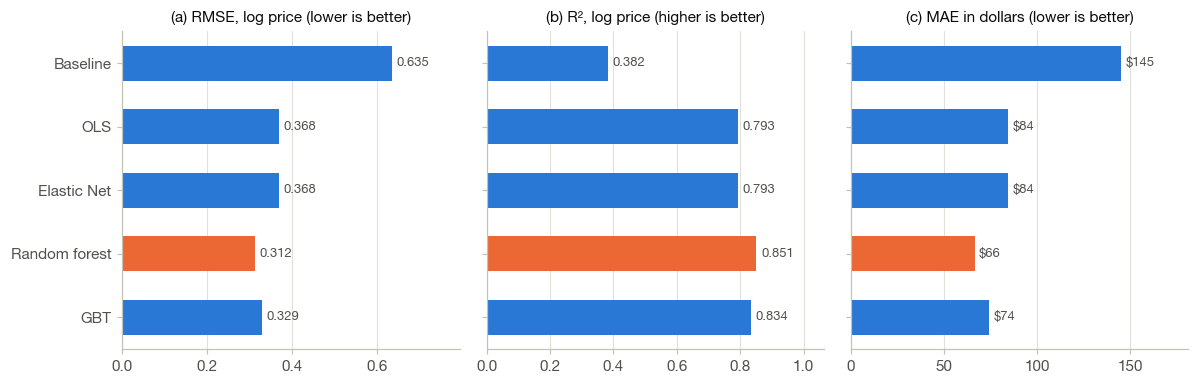

In [18]:
order = ["Baseline (neighborhood × room median)", "OLS linear regression", "Elastic Net linear regression",
         "Random forest", "Gradient-boosted trees"]
short = {"Baseline (neighborhood × room median)": "Baseline", "OLS linear regression": "OLS",
         "Elastic Net linear regression": "Elastic Net", "Random forest": "Random forest", "Gradient-boosted trees": "GBT"}
c = comparison.set_index("model").loc[order]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, col, title, fmt in [(axes[0], "rmse_log", "(a) RMSE, log price (lower is better)", "{:.3f}"),
                            (axes[1], "r2_log", "(b) R², log price (higher is better)", "{:.3f}"),
                            (axes[2], "mae_usd", "(c) MAE in dollars (lower is better)", "${:,.0f}")]:
    colors = [ps.SERIES[1] if m == best_name else ps.SERIES[0] for m in order]
    bars = ax.barh([short[m] for m in order], c[col], color=colors, height=0.55)
    ax.bar_label(bars, labels=[fmt.format(v) for v in c[col]], padding=3, fontsize=8.5, color=ps.INK2)
    ax.set_title(title, fontsize=10)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, c[col].max() * 1.25)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.tight_layout()
ps.save(fig, FIG_DIR, "figM1_model_comparison")

**Figure M2 — Predicted versus actual price, best model (test set).**

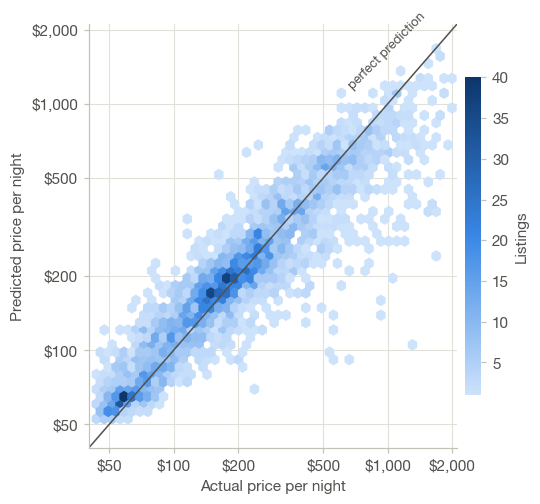

In [19]:
pa = best_pred.select("price", "pred_price").toPandas()
fig, ax = plt.subplots(figsize=(5.2, 5))
hb = ax.hexbin(pa.price, pa.pred_price, gridsize=45, xscale="log", yscale="log", mincnt=1,
               cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#cde2fb", "#3987e5", "#0d366b"]))
lims = [40, 2100]
ax.plot(lims, lims, color=ps.INK2, lw=1)
ax.annotate("perfect prediction", (1000, 1150), color=ps.INK2, fontsize=8.5, rotation=45, ha="center")
ax.set(xlim=lims, ylim=lims, xlabel="Actual price per night", ylabel="Predicted price per night")
ticks = [50, 100, 200, 500, 1000, 2000]
ax.set_xticks(ticks, [f"${t:,}" for t in ticks]); ax.set_yticks(ticks, [f"${t:,}" for t in ticks])
ax.minorticks_off()
cb = fig.colorbar(hb, ax=ax, shrink=0.75, pad=0.02); cb.outline.set_visible(False); cb.set_label("Listings", color=ps.INK2)
ps.save(fig, FIG_DIR, "figM2_predicted_vs_actual")

**Figure M3 — Permutation importance by feature family.**

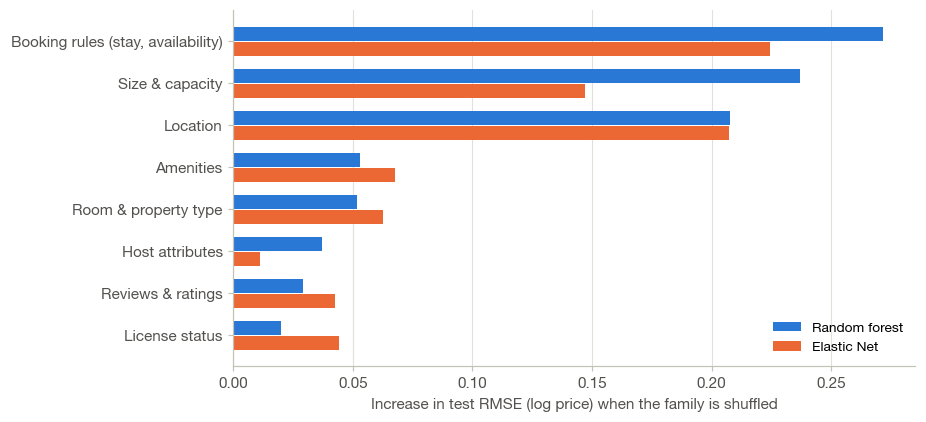

In [20]:
pv = perm.pivot(index="group", columns="model", values="rmse_increase").sort_values(best_name)
y = np.arange(len(pv))
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (m, color) in enumerate([(best_name, ps.SERIES[0]), ("Elastic Net linear regression", ps.SERIES[1])]):
    ax.barh(y + (0.5 - i) * 0.36, pv[m], height=0.34, color=color, label=short[m])
ax.set_yticks(y, pv.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Increase in test RMSE (log price) when the family is shuffled")
ax.legend(loc="lower right")
ps.save(fig, FIG_DIR, "figM3_permutation_importance")

**Figure M4 — Largest Elastic Net effects (standardized).**

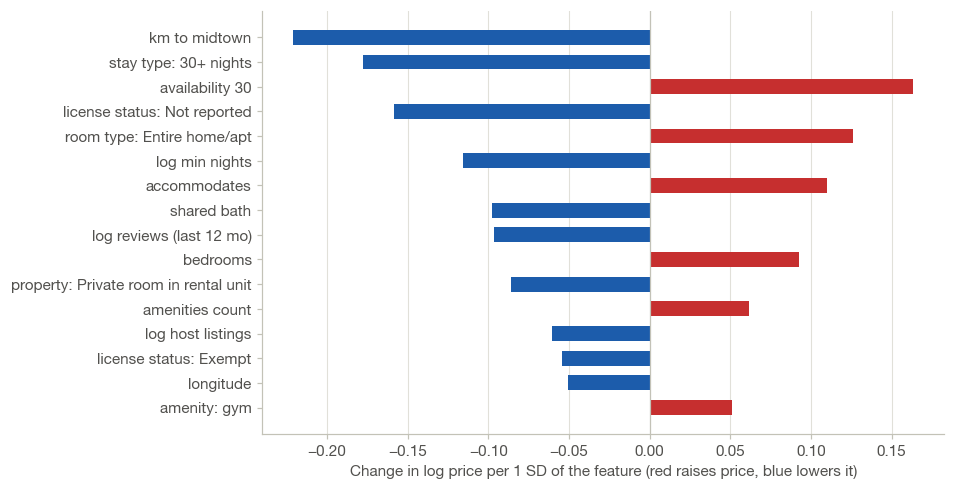

In [21]:
top = coef.head(16).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.label, top.std_coef, color=[ps.POS if v > 0 else ps.NEG for v in top.std_coef], height=0.6)
ax.axvline(0, color=ps.AXIS, lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Change in log price per 1 SD of the feature (red raises price, blue lowers it)")
ps.save(fig, FIG_DIR, "figM4_elastic_net_effects")

**Figure M5 — Top individual features in the best tree model (impurity importance).**

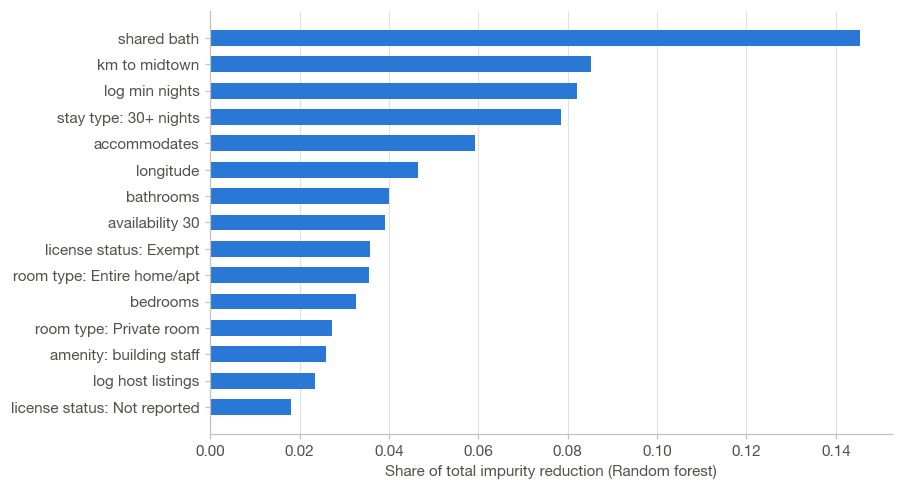

In [22]:
ti = tree_imp[tree_imp.model == best_name].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(ti.label, ti.importance, color=ps.SERIES[0], height=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Share of total impurity reduction ({short[best_name]})")
ps.save(fig, FIG_DIR, "figM5_tree_importance")

**Figure M6 — Prediction error by segment (best model).**

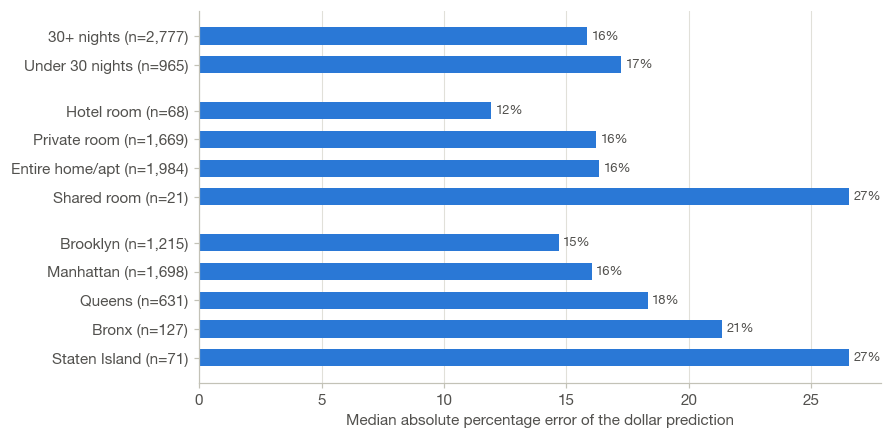

In [23]:
s = segments.copy()
s["label"] = s.segment
s = s[s.test_listings >= 20].sort_values(["dimension", "median_abs_pct_error"])
fig, ax = plt.subplots(figsize=(8, 4.4))
dims = {"stay_type": "Stay type", "room_type": "Room type", "borough": "Borough"}
ypos, labels, ycur = [], [], 0
for d in ["stay_type", "room_type", "borough"]:
    for _, r in s[s.dimension == d].iterrows():
        ypos.append(ycur); labels.append(f"{r.label} (n={r.test_listings:,})"); ycur += 1
    ycur += 0.6
vals = pd.concat([s[s.dimension == d] for d in ["stay_type", "room_type", "borough"]]).median_abs_pct_error * 100
bars = ax.barh(ypos, vals, color=ps.SERIES[0], height=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in vals], padding=3, fontsize=8.5, color=ps.INK2)
ax.set_yticks(ypos, labels)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Median absolute percentage error of the dollar prediction")
ps.save(fig, FIG_DIR, "figM6_error_by_segment")

## 13. Wrap-up

In [24]:
print("Best model:", best_name)
print(comparison.set_index("model")[["rmse_log", "r2_log", "rmse_usd", "mae_usd", "median_abs_pct_error"]].round(3).to_string())
spark.stop()

Best model: Random forest
                                       rmse_log  r2_log  rmse_usd  mae_usd  median_abs_pct_error
model                                                                                           
Baseline (neighborhood × room median)     0.635   0.382   225.062  144.776                 0.510
OLS linear regression                     0.368   0.793   164.439   84.381                 0.225
Elastic Net linear regression             0.368   0.793   164.372   84.246                 0.226
Random forest                             0.312   0.851   141.508   66.362                 0.162
Gradient-boosted trees                    0.329   0.834   149.504   74.145                 0.191
